# IE492 — Aşama 1: Renk bazlı FCFS satranç eşleştirmesi (terkli model)

**Model**
- Oyuncular Poisson($\lambda$) süreciyle gelir.
- Her oyuncu $p$ olasılıkla **beyaz**, $1-p$ olasılıkla **siyah**.
- FCFS: sıranın başındaki beyaz ile sıranın başındaki siyah anında eşleşir. Bu yüzden aynı anda yalnızca tek renk bekleyebilir.
- **Terk:** her bekleyen oyuncunun sabrı $\text{Exp}(\theta)$; sabrı biten oyuncu kuyruktan ayrılır.

**KPI'lar (renk bazında):** eşleşme oranı, terk oranı, ortalama / medyan / p90 bekleme, hiç beklemeden eşleşme oranı, zaman ortalamalı kuyruk uzunluğu (ayrı ayrı ve toplam $E[|X|]$).

**Analitik karşılaştırma:** $X(t) = \#\text{beyaz} - \#\text{siyah}$ bir doğum-ölüm zinciri (CTMC).
- FCFS nedeniyle aynı anda iki renk birden kuyrukta olamaz. Dolayısıyla herhangi bir $t$ anında sistemdeki **toplam kuyruk uzunluğu** $|X(t)| = |\#\text{beyaz} - \#\text{siyah}|$'dir.
- Zaman ortalamalı toplam kuyruk $L_\text{toplam} = L_\text{beyaz} + L_\text{siyah} = E[|X|]$.
- $n>0$ iken $n \to n+1$ hızı $p\lambda$, $n \to n-1$ hızı $(1-p)\lambda + n\theta$; $n<0$ tarafı simetrik. Durağan dağılımdan Little yasasıyla:
$$E[W_\text{beyaz}] = \frac{L_\text{beyaz}}{p\lambda}, \qquad P(\text{beyaz terk}) = \frac{\theta L_\text{beyaz}}{p\lambda}$$


In [1]:
import heapq
import math
from collections import deque

import numpy as np
import matplotlib.pyplot as plt

WHITE, BLACK = 0, 1
COLOR_NAME = {WHITE: "beyaz", BLACK: "siyah"}
WAITING, MATCHED, ABANDONED = 0, 1, 2

## Parametreler
Zaman birimi = ortalama gelişler arası süre ($\lambda = 1$ ise dakika gibi düşünülebilir).

In [2]:
LAM = 1.0        # gelis hizi
P = 0.6          # beyaz olma olasiligi
THETA = 0.05     # terk hizi (ortalama sabir = 1/THETA)
T = 100_000      # simulasyon suresi
WARMUP = 1_000   # isinma suresi, KPI'lara dahil edilmez
SEED = 42

## Simülasyon
Olay tabanlı simülasyon. Terk olayları bir heap'te tutulur; kuyrukta terk etmiş oyuncular eşleşme anında atlanır (lazy deletion).

In [3]:
def simulate(lam, p, theta, T, warmup=0.0, seed=None):
    rng = np.random.default_rng(seed)

    # oyuncu bazli kayitlar (indeks = oyuncu id)
    arrival, color, end, status = [], [], [], []

    queues = {WHITE: deque(), BLACK: deque()}
    n_waiting = {WHITE: 0, BLACK: 0}
    abandon_heap = []  # (son_tarih, oyuncu_id)

    # zaman ortalamali kuyruk uzunlugu ve iz
    area = {WHITE: 0.0, BLACK: 0.0}
    last_t = 0.0
    trace_t, trace_x = [0.0], [0]

    def advance(to):
        nonlocal last_t
        start = max(last_t, warmup)
        if to > start:
            for c in (WHITE, BLACK):
                area[c] += n_waiting[c] * (to - start)
        last_t = to

    def record_trace(t):
        trace_t.append(t)
        trace_x.append(n_waiting[WHITE] - n_waiting[BLACK])

    t = 0.0
    while True:
        t_next = t + rng.exponential(1 / lam)

        # bir sonraki gelisten once gerceklesen terkler
        while abandon_heap and abandon_heap[0][0] <= min(t_next, T):
            d, i = heapq.heappop(abandon_heap)
            if status[i] == WAITING:
                advance(d)
                status[i], end[i] = ABANDONED, d
                n_waiting[color[i]] -= 1
                record_trace(d)

        if t_next > T:
            advance(T)
            break

        t = t_next
        advance(t)
        c = WHITE if rng.random() < p else BLACK
        other = 1 - c

        i = len(arrival)
        arrival.append(t); color.append(c); end.append(np.nan); status.append(WAITING)

        # karsi renkte sira basindaki (hala bekleyen) oyuncuyu bul
        partner = None
        while queues[other]:
            j = queues[other].popleft()
            if status[j] == WAITING:
                partner = j
                break

        if partner is not None:
            status[partner], end[partner] = MATCHED, t
            status[i], end[i] = MATCHED, t
            n_waiting[other] -= 1
        else:
            queues[c].append(i)
            n_waiting[c] += 1
            if theta > 0:
                heapq.heappush(abandon_heap, (t + rng.exponential(1 / theta), i))
        record_trace(t)

    players = {
        "arrival": np.array(arrival),
        "color": np.array(color),
        "end": np.array(end),
        "status": np.array(status),
    }
    span = T - warmup
    avg_queue = {c: area[c] / span for c in (WHITE, BLACK)}
    trace = (np.array(trace_t), np.array(trace_x))
    return players, avg_queue, trace

## KPI hesabı
Isınma süresinden önce gelenler ve simülasyon sonunda hâlâ bekleyenler (sansürlü) KPI'lara dahil edilmez.

In [4]:
def compute_kpis(players, avg_queue, warmup=0.0):
    kpis = {}
    for c in (WHITE, BLACK):
        sel = (players["color"] == c) & (players["arrival"] >= warmup) & (players["status"] != WAITING)
        st = players["status"][sel]
        w = players["end"][sel] - players["arrival"][sel]
        w_matched = w[st == MATCHED]
        kpis[COLOR_NAME[c]] = {
            "oyuncu sayisi": int(sel.sum()),
            "eslesme orani": float((st == MATCHED).mean()),
            "terk orani": float((st == ABANDONED).mean()),
            "ort. bekleme (tumu)": float(w.mean()),
            "ort. bekleme (eslesen)": float(w_matched.mean()),
            "medyan bekleme (eslesen)": float(np.median(w_matched)),
            "p90 bekleme (eslesen)": float(np.percentile(w_matched, 90)),
            "beklemeden eslesme orani": float((w == 0).mean()),
            "ort. kuyruk uzunlugu": avg_queue[c],
        }
    kpis["toplam"] = {
        "ort. kuyruk uzunlugu": avg_queue[WHITE] + avg_queue[BLACK]
    }
    return kpis


def print_kpis(kpis):
    names = [k for k in next(iter(kpis.values())).keys()]
    print(f"{'KPI':<28}{'beyaz':>12}{'siyah':>12}")
    for n in names:
        print(f"{n:<28}{kpis['beyaz'][n]:>12.3f}{kpis['siyah'][n]:>12.3f}")
    if "toplam" in kpis:
        print(f"{'ort. toplam kuyruk (|B-S|)':<28}{kpis['toplam']['ort. kuyruk uzunlugu']:>24.3f}")


## Analitik model (CTMC)

In [5]:
def ctmc_abandon(lam, p, theta, N=500):
    # durum n: n>0 -> n beyaz bekliyor, n<0 -> |n| siyah bekliyor
    a, b = p * lam, (1 - p) * lam
    log_pi = {0: 0.0}
    for n in range(1, N):
        log_pi[n] = log_pi[n - 1] + math.log(a) - math.log(b + n * theta)
        log_pi[-n] = log_pi[-(n - 1)] + math.log(b) - math.log(a + n * theta)
    m = max(log_pi.values())
    pi = {n: math.exp(v - m) for n, v in log_pi.items()}
    Z = sum(pi.values())
    L_w = sum(n * v for n, v in pi.items() if n > 0) / Z
    L_b = sum(-n * v for n, v in pi.items() if n < 0) / Z
    return {
        "beyaz": {"ort. bekleme (tumu)": L_w / a, "terk orani": theta * L_w / a, "ort. kuyruk uzunlugu": L_w},
        "siyah": {"ort. bekleme (tumu)": L_b / b, "terk orani": theta * L_b / b, "ort. kuyruk uzunlugu": L_b},
        "toplam": {"ort. kuyruk uzunlugu": L_w + L_b},
    }


## Tek senaryo

In [6]:
players, avg_queue, trace = simulate(LAM, P, THETA, T, WARMUP, seed=SEED)
kpis = compute_kpis(players, avg_queue, WARMUP)
print_kpis(kpis)

print("\nSimulasyon vs CTMC")
theory = ctmc_abandon(LAM, P, THETA)
for col in ('beyaz', 'siyah'):
    for k in ('ort. bekleme (tumu)', 'terk orani', 'ort. kuyruk uzunlugu'):
        print(f"{col:<6} {k:<22} sim={kpis[col][k]:8.3f}   ctmc={theory[col][k]:8.3f}")
print(f"{'toplam':<6} {'ort. kuyruk (|X|)':<22} sim={kpis['toplam']['ort. kuyruk uzunlugu']:8.3f}   ctmc={theory['toplam']['ort. kuyruk uzunlugu']:8.3f}")

print(f"\nCogunluk rengi icin terk alt siniri (2p-1)/p = {max(2*P-1, 0)/P:.3f}")


KPI                                beyaz       siyah
oyuncu sayisi                  59427.000   39729.000
eslesme orani                      0.653       0.977
terk orani                         0.347       0.023
ort. bekleme (tumu)                6.964       0.456
ort. bekleme (eslesen)             7.524       0.402
medyan bekleme (eslesen)           6.676       0.000
p90 bekleme (eslesen)             16.023       0.975
beklemeden eslesme orani           0.089       0.844
ort. kuyruk uzunlugu               4.181       0.183

Simulasyon vs CTMC
beyaz  ort. bekleme (tumu)    sim=   6.964   ctmc=   6.962
beyaz  terk orani             sim=   0.347   ctmc=   0.348
beyaz  ort. kuyruk uzunlugu   sim=   4.181   ctmc=   4.177
siyah  ort. bekleme (tumu)    sim=   0.456   ctmc=   0.443
siyah  terk orani             sim=   0.023   ctmc=   0.022
siyah  ort. kuyruk uzunlugu   sim=   0.183   ctmc=   0.177

Cogunluk rengi icin terk alt siniri (2p-1)/p = 0.333


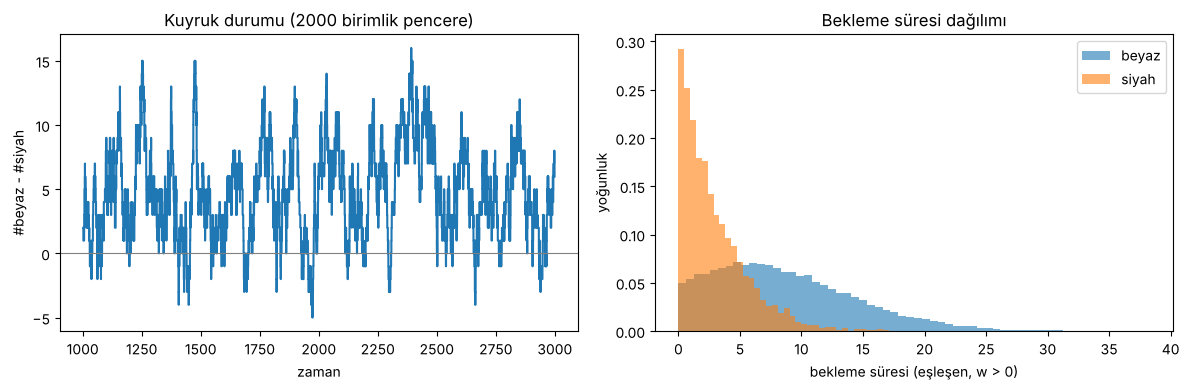

In [7]:
fig, axs = plt.subplots(1, 3, figsize=(16, 4))

tt, xx = trace
window = (tt >= WARMUP) & (tt <= WARMUP + 2000)

# 1. Isaretli kuyruk farki (X(t) = #beyaz - #siyah)
axs[0].step(tt[window], xx[window], where="post", color="tab:blue")
axs[0].axhline(0, color="gray", lw=0.8, linestyle="--")
axs[0].set_xlabel("zaman")
axs[0].set_ylabel("#beyaz - #siyah")
axs[0].set_title("Kuyruk Farkı: X(t)")

# 2. Herhangi bir andaki toplam kuyruk: |X(t)|
abs_xx = np.abs(xx)
axs[1].step(tt[window], abs_xx[window], where="post", color="tab:purple")
axs[1].axhline(kpis["toplam"]["ort. kuyruk uzunlugu"], color="red", linestyle=":", lw=1.5,
                label=f"Ort. = {kpis['toplam']['ort. kuyruk uzunlugu']:.2f}")
axs[1].set_xlabel("zaman")
axs[1].set_ylabel("Anlık Toplam Kuyruk |X(t)|")
axs[1].set_title("Anlık Toplam Kuyruk: |beyaz - siyah|")
axs[1].legend()

# 3. Bekleme suresi dagilimi
for c in (WHITE, BLACK):
    sel = (players["color"] == c) & (players["status"] == MATCHED) & (players["arrival"] >= WARMUP)
    w = players["end"][sel] - players["arrival"][sel]
    axs[2].hist(w[w > 0], bins=60, alpha=0.6, label=COLOR_NAME[c], density=True)
axs[2].set_xlabel("bekleme süresi (eşleşen, w > 0)")
axs[2].set_ylabel("yoğunluk")
axs[2].set_title("Bekleme Süresi Dağılımı")
axs[2].legend()
plt.tight_layout()
plt.show()


## Duyarlılık analizi: $p$ ve $\theta$

In [8]:
P_GRID = [0.5, 0.55, 0.6, 0.7]
THETA_GRID = [0.01, 0.05, 0.2]
T_SWEEP = 100_000

rows = []
for theta in THETA_GRID:
    for p in P_GRID:
        pl, aq, _ = simulate(LAM, p, theta, T_SWEEP, WARMUP, seed=SEED)
        k = compute_kpis(pl, aq, WARMUP)
        th = ctmc_abandon(LAM, p, theta)
        rows.append((p, theta, k, th))

print(f"{'p':>5}{'theta':>7} | {'W bekleme sim':>13}{'ctmc':>8} | {'W terk sim':>10}{'ctmc':>8} | {'S bekleme sim':>13}{'ctmc':>8} | {'S terk sim':>10}{'ctmc':>8}")
for p, theta, k, th in rows:
    print(f"{p:>5}{theta:>7} | "
          f"{k['beyaz']['ort. bekleme (tumu)']:>13.2f}{th['beyaz']['ort. bekleme (tumu)']:>8.2f} | "
          f"{k['beyaz']['terk orani']:>10.3f}{th['beyaz']['terk orani']:>8.3f} | "
          f"{k['siyah']['ort. bekleme (tumu)']:>13.2f}{th['siyah']['ort. bekleme (tumu)']:>8.2f} | "
          f"{k['siyah']['terk orani']:>10.3f}{th['siyah']['terk orani']:>8.3f}")

    p  theta | W bekleme sim    ctmc | W terk sim    ctmc | S bekleme sim    ctmc | S terk sim    ctmc
  0.5   0.01 |          6.43    5.74 |      0.064   0.057 |          5.21    5.74 |      0.053   0.057
 0.55   0.01 |         18.60   18.68 |      0.187   0.187 |          0.60    0.61 |      0.006   0.006
  0.6   0.01 |         33.40   33.34 |      0.334   0.333 |          0.01    0.02 |      0.000   0.000
  0.7   0.01 |         57.15   57.14 |      0.570   0.571 |          0.00    0.00 |      0.000   0.000
  0.5   0.05 |          2.72    2.61 |      0.135   0.130 |          2.55    2.61 |      0.129   0.130
 0.55   0.05 |          4.58    4.62 |      0.230   0.231 |          1.23    1.21 |      0.063   0.060
  0.6   0.05 |          6.96    6.96 |      0.347   0.348 |          0.46    0.44 |      0.023   0.022
  0.7   0.05 |         11.45   11.44 |      0.571   0.572 |          0.04    0.03 |      0.002   0.001
  0.5    0.2 |          1.33    1.32 |      0.268   0.264 |          1.32

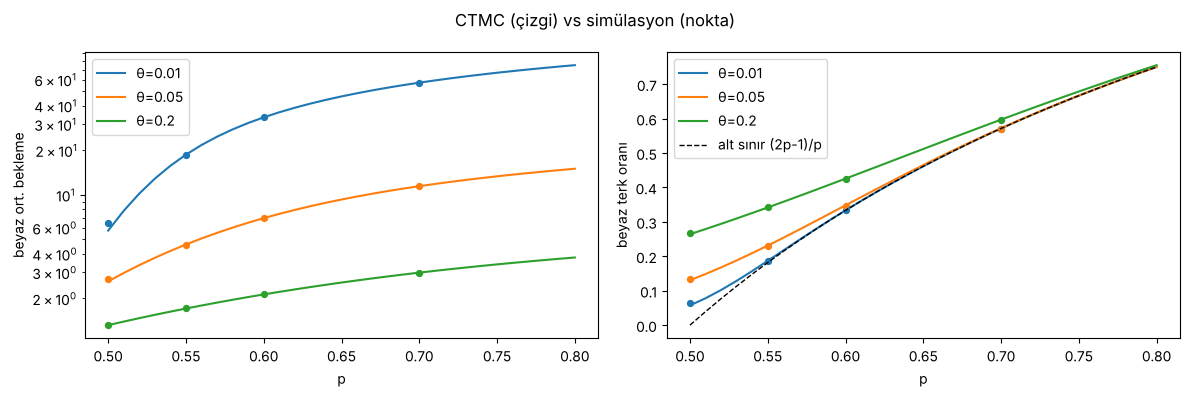

In [9]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4))
ps = np.linspace(0.5, 0.8, 31)
for theta in THETA_GRID:
    th = [ctmc_abandon(LAM, p, theta) for p in ps]
    line, = axs[0].plot(ps, [x["beyaz"]["ort. bekleme (tumu)"] for x in th], label=f"θ={theta}")
    axs[1].plot(ps, [x["beyaz"]["terk orani"] for x in th], color=line.get_color(), label=f"θ={theta}")
    sim = [(p, k) for p, t_, k, _ in rows if t_ == theta]
    axs[0].scatter([p for p, _ in sim], [k["beyaz"]["ort. bekleme (tumu)"] for _, k in sim], color=line.get_color(), s=18)
    axs[1].scatter([p for p, _ in sim], [k["beyaz"]["terk orani"] for _, k in sim], color=line.get_color(), s=18)
axs[1].plot(ps, (2 * ps - 1) / ps, "k--", lw=1, label="alt sınır (2p-1)/p")
axs[0].set_yscale("log")
axs[0].set_xlabel("p"); axs[0].set_ylabel("beyaz ort. bekleme")
axs[1].set_xlabel("p"); axs[1].set_ylabel("beyaz terk oranı")
for a in axs: a.legend()
fig.suptitle("CTMC (çizgi) vs simülasyon (nokta)")
plt.tight_layout(); plt.show()

## Not: terk olmasaydı ($\theta = 0$)
Sistem hiçbir $p$ için kararlı olmaz: $p \ne 0.5$ iken çoğunluk renginin kuyruğu $\approx |2p-1|\lambda t$ hızla doğrusal büyür; $p = 0.5$ iken medyan bekleme küçüktür ama $E[W] = \infty$ (null-recurrent rastgele yürüyüş). Aşağıdaki hücre bunu gösterir.

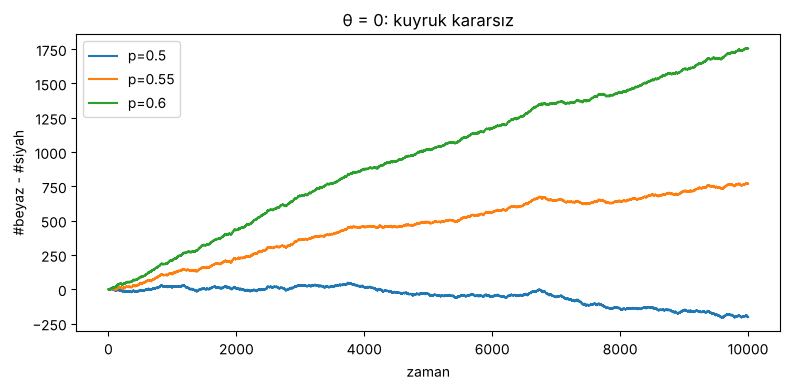

In [10]:
fig, ax = plt.subplots(figsize=(8, 4))
for p in [0.5, 0.55, 0.6]:
    _, _, (tt, xx) = simulate(LAM, p, 0.0, 10_000, seed=SEED)
    ax.plot(tt, xx, label=f"p={p}")
ax.set_xlabel("zaman"); ax.set_ylabel("#beyaz - #siyah")
ax.set_title("θ = 0: kuyruk kararsız")
ax.legend(); plt.tight_layout(); plt.show()